ANIMA usw. entfernt, nicht Teil der Aufgabe und zu viel  
Jahressaisonalität als Ergänzung hinzugefügt  
STL umgeschrieben, da wir jetzt einfach lin Trend benutzen, kann man besser formulieren  
ACF Erklärung  
lin reg kompakter gefasst  
Erkenntnisse hinzugeschrieben, motto: why use many word when few do trick? ggf. ergänzen  
  
TODO:  
Jahressaisonalität bei manueller Zerlegung rausrechnen? -> Aufgabe 3  
Vergleich Tarife Erkenntnisse  
Diesen Text entfernen

In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

---

## Vorverarbeitung der Daten

In [2]:
df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt, "date" wird dabei als Index übernommen
df = df.groupby("date").agg({"KWH": "sum", "meters": "sum"})

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df = df.rename(columns={"KWH": "kwh"})

df = df[["kwh", "meters"]]
df

,kwh,meters
date,,
2011-11-23 09:00:00,0.569000,2
2011-11-23 09:30:00,0.561000,2
2011-11-23 10:00:00,0.920000,6
2011-11-23 10:30:00,0.588000,6
2011-11-23 11:00:00,0.772000,7
...,...,...
2014-02-27 22:00:00,1494.603000,4986
2014-02-27 22:30:00,1422.109001,4987
2014-02-27 23:00:00,1258.090000,4987


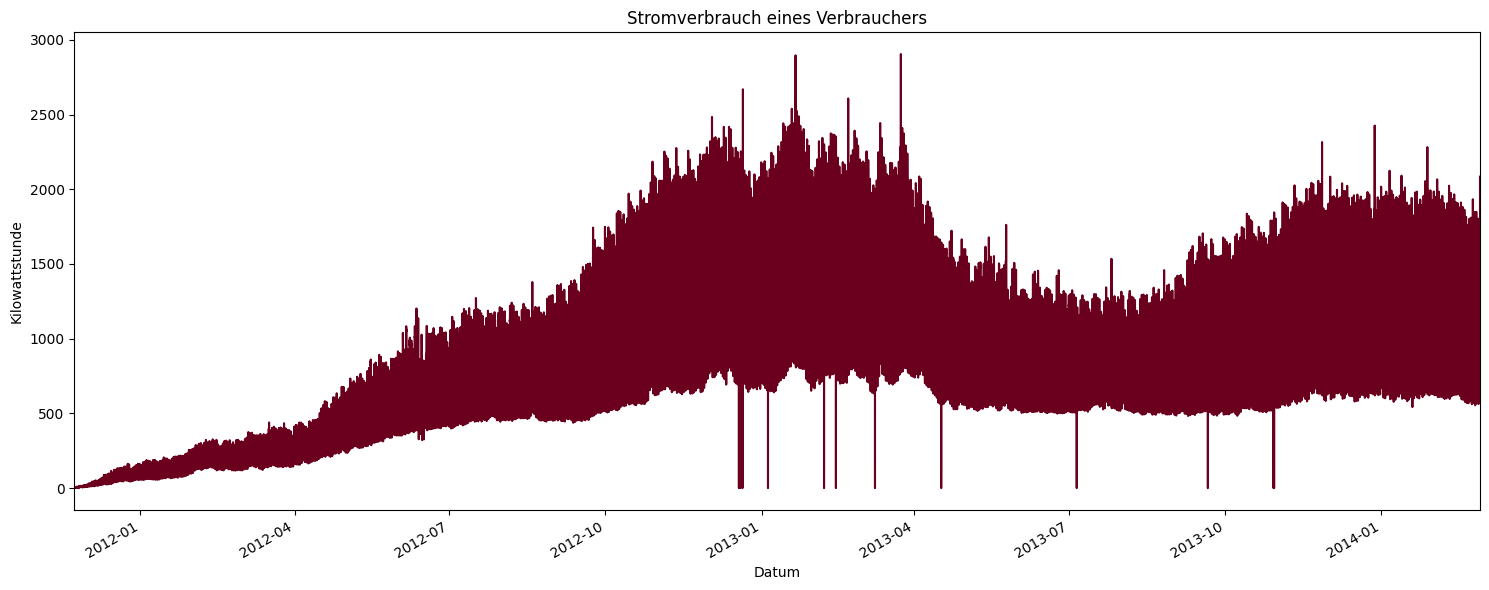

In [3]:
# Erste Visualisierung des Datensatzes
series = df["kwh"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Stromverbrauch eines Verbrauchers",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

---

## Datenbereinigung

Im Datensatz sind fehlerhaft Datenpunkte enthalten, bei denen kein Verbraucher geschaltet ist und die Messungen außerhalb dem 30-Minuten-Taktes liegen.

In [4]:
# Prüfung auf Datenpunkte mit keinem Verbrauch
display(df.loc[(df["kwh"] == 0)])

# Falls die Prüfungen nichts zurückliefern, können die fehlerhaften Datenpunkte entfernt werden
# Prüfung auf korrekte Datenpunkte mit keinem Verbrauch
display(df.loc[(df["kwh"] == 0) & ((df.index.minute % 30 == 0) & (df.index.second == 0))])
# Prüfung auf korrekte Datenpunkte außerhalb des 30-Minuten-Taktes
display(df.loc[~(df["kwh"] == 0) & ~((df.index.minute % 30 == 0) & (df.index.second == 0))])

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.sort_index().asfreq("30min")
df["kwh"].isna().sum()

,kwh,meters
date,,
2012-12-18 15:13:26,0.0,0
2012-12-18 15:13:27,0.0,0
2012-12-18 15:13:28,0.0,0
2012-12-18 15:13:29,0.0,0
2012-12-18 15:13:30,0.0,0
...,...,...
2013-07-05 12:54:31,0.0,0
2013-07-05 13:15:05,0.0,0
2013-09-20 18:24:09,0.0,0


,kwh,meters
date,,


,kwh,meters
date,,


np.int64(0)

---

## Untersuchung der Zeitreihe auf Trend, Saisonalität und Residuum

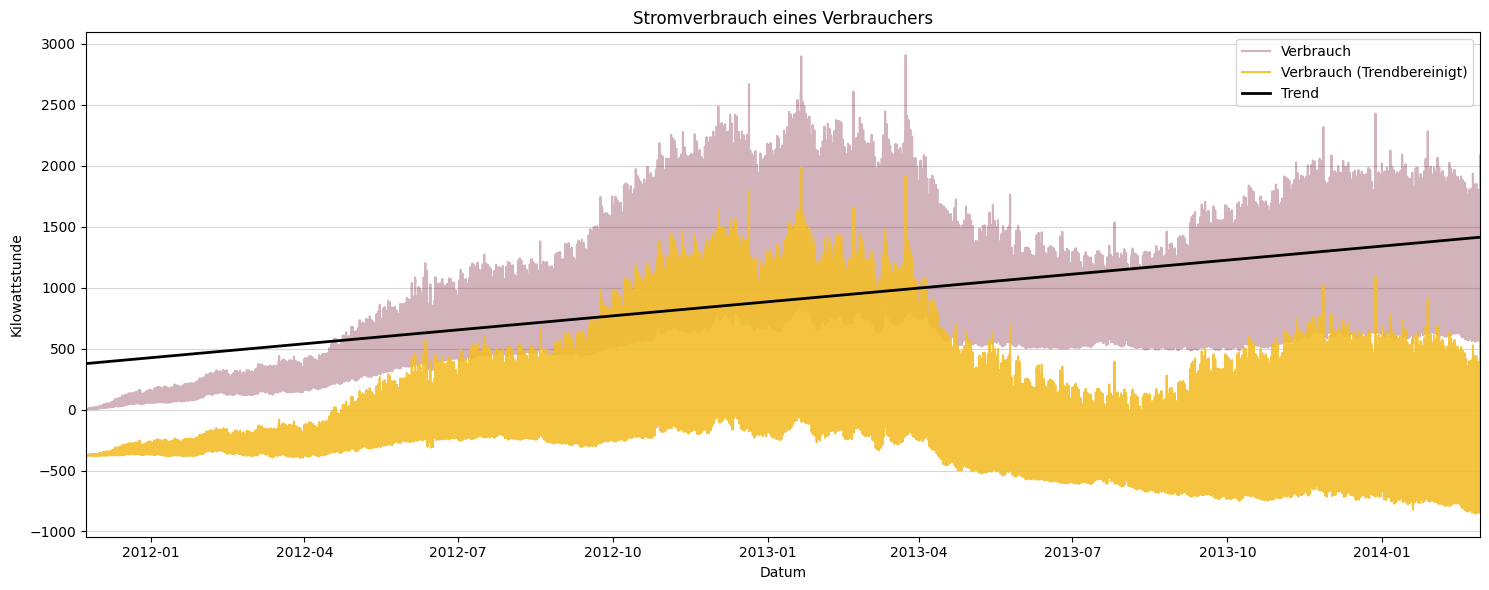

In [5]:
def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    # Berechnung des linearen Trends der Zeitreihe
    x = mdates.date2num(df.index)
    p = np.poly1d(np.polyfit(x, df["kwh"], 1))
    df["kwh_trend"] = p(x)

    # Der Stromverbrauch bereinigt vom Trend
    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]

    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.9, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, linewidth=2, label="Trend")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return df


df = analyse_trend(df)

<font color="orange">
Erkenntnisse: Es ist ein schwach fallender Trend zu erkennen - Stromverbrauch nimmt über die Zeit ab (auch, wenn man als Zeitraum volle Jahre nimmt, also vom 01.01.2012 bis 01.01.2014).
</font>

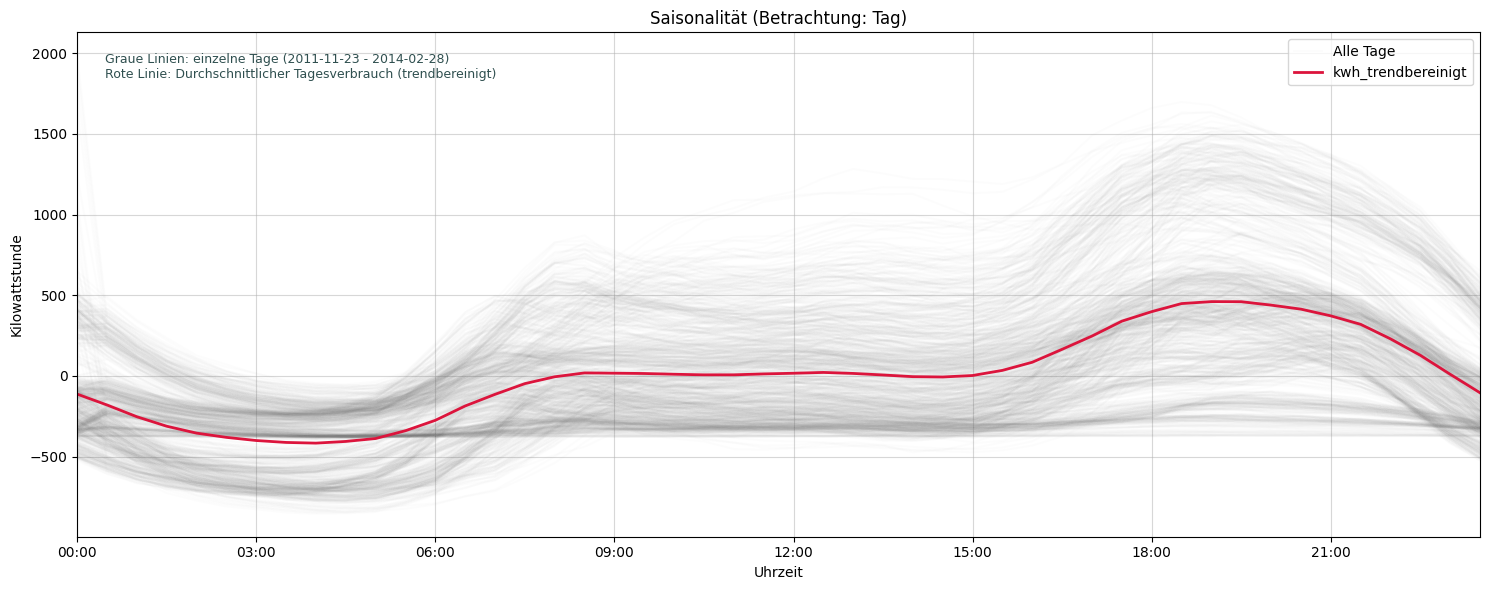

In [6]:
def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    df["focus"] = df.index.hour * 2 + (df.index.minute // 30)  # Fokus auf einen Tag setzen

    # Der Mittelwert aller 30-Minuten Intervalle eines Tages
    seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    # Verbrauch aller Tage zur Veranschaulichung
    df["pivot_date"] = df.index.date  # Pivot arbeitet effizienter als die for-Schleife, die Logik ist aber die selbe
    pivot_data = df.pivot_table(index="focus", columns="pivot_date", values="kwh_trendbereinigt")

    lines = ax.plot(pivot_data, color="gray", alpha=0.02)
    if lines:
        lines[0].set_label("Alle Tage")

    seasonal.plot(ax=ax, color="crimson", linewidth=2)
    ax.set(
        title="Saisonalität (Betrachtung: Tag)",
        xlabel="Uhrzeit",
        ylabel="Kilowattstunde",
    )

    ax.text(
        0.02,
        0.96,
        f"Graue Linien: einzelne Tage ({pivot_data.columns.min()} - {pivot_data.columns.max()})\nRote Linie: Durchschnittlicher Tagesverbrauch (trendbereinigt)",
        transform=ax.transAxes,
        fontsize=9,
        color="darkslategray",
        verticalalignment="top",
    )

    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # .transform berechnet den Mittelwert pro Gruppe und weist ihn jedem Datenpunkt der Gruppe zu
    df["kwh_trendbereinigt_saison"] = df.groupby("focus")["kwh_trendbereinigt"].transform("mean")
    return df.drop(columns=["focus", "pivot_date"])


df = analyse_seasonality(df)

<font color="orange">
Erkenntnisse: Wie erwartet fällt der Stromverbrauch nachts sehr stark, nimmt im Laufe des Mittags zu und erreicht seinen Höhepunkt abends, wenn jeder wieder zu Hause ist.
</font>

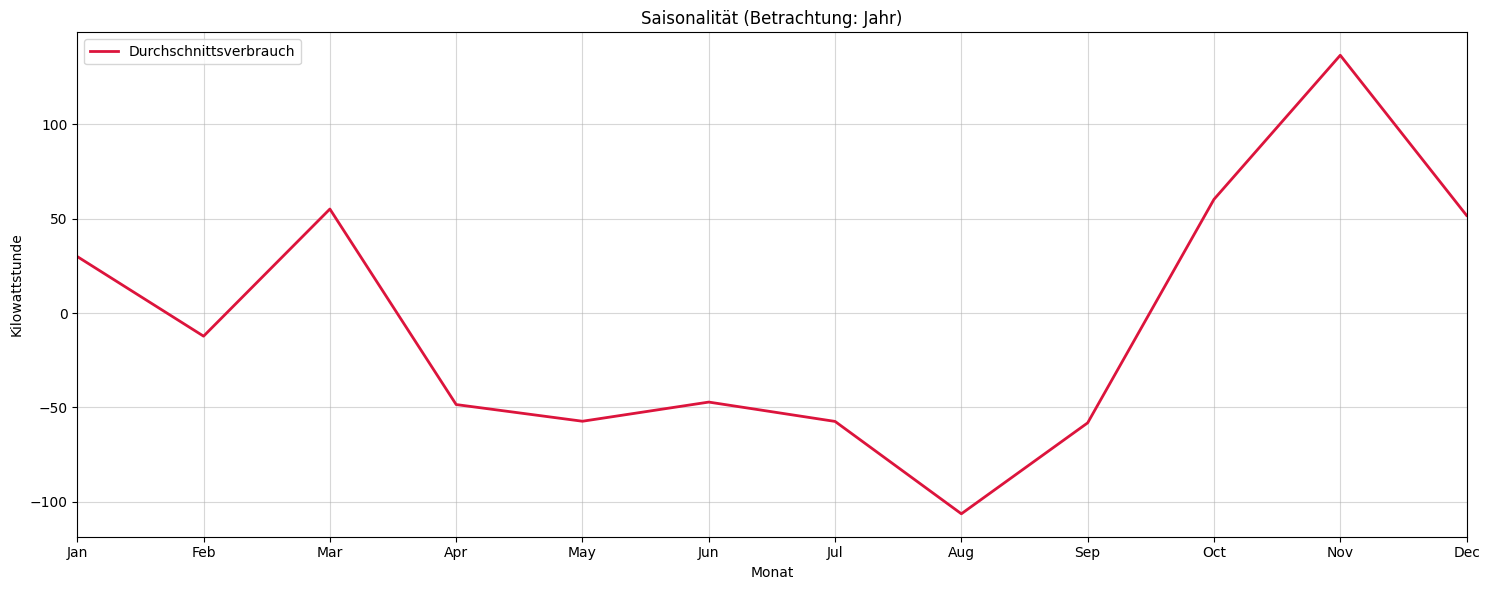

In [7]:
# Ergänzend
def analyse_seasonality_year(df: pd.DataFrame) -> None:
    df_year = df.copy()

    # Fokus auf ein Jahr setzen
    df_year["focus"] = df_year.index.month

    seasonal = df_year.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    seasonal.plot(ax=ax, color="crimson", alpha=1, label="Durchschnittsverbrauch", linewidth=2)  ##031E81 Ursprüngliche Farbe
    ax.set(
        title="Saisonalität (Betrachtung: Jahr)",
        xlabel="Monat",
        ylabel="Kilowattstunde",
    )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(pd.Series(range(1, 13)).map(lambda x: pd.to_datetime(x, format="%m").strftime("%b")))
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


analyse_seasonality_year(df)

<font color="orange">
Erkenntnisse: Im den Wintermonaten wird deutlich mehr Strom verbraucht als im Sommer.
</font>

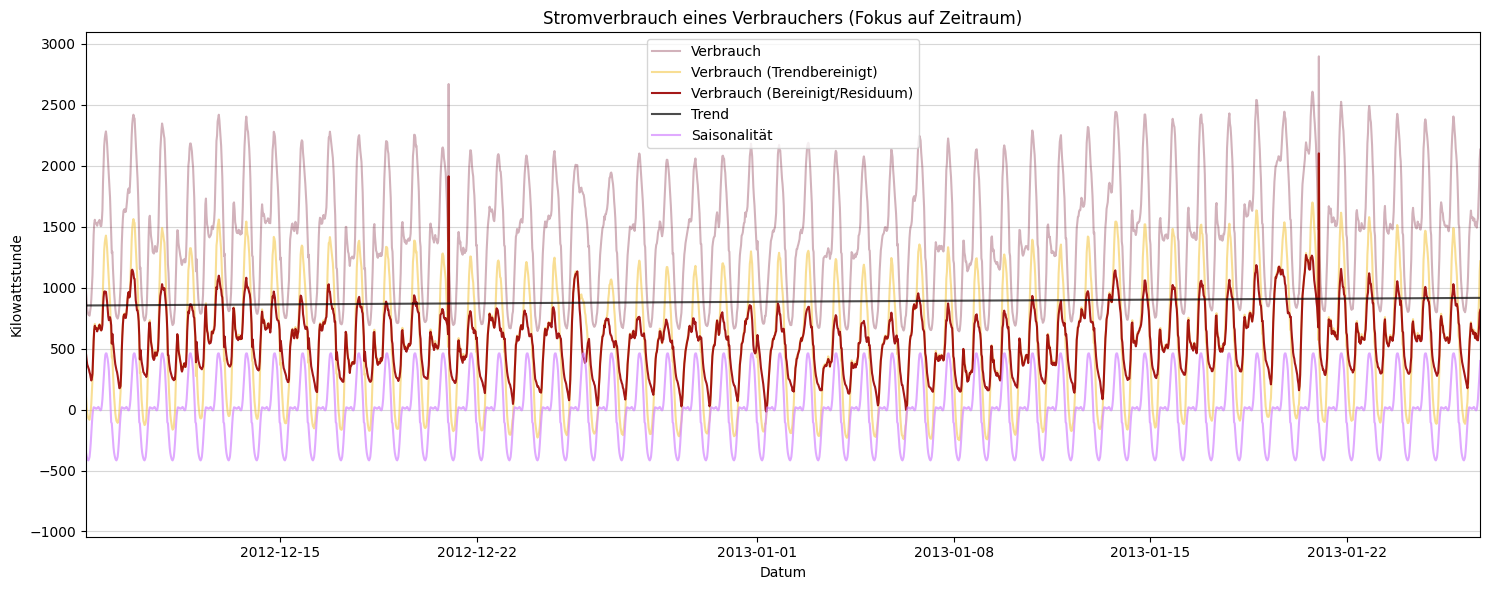

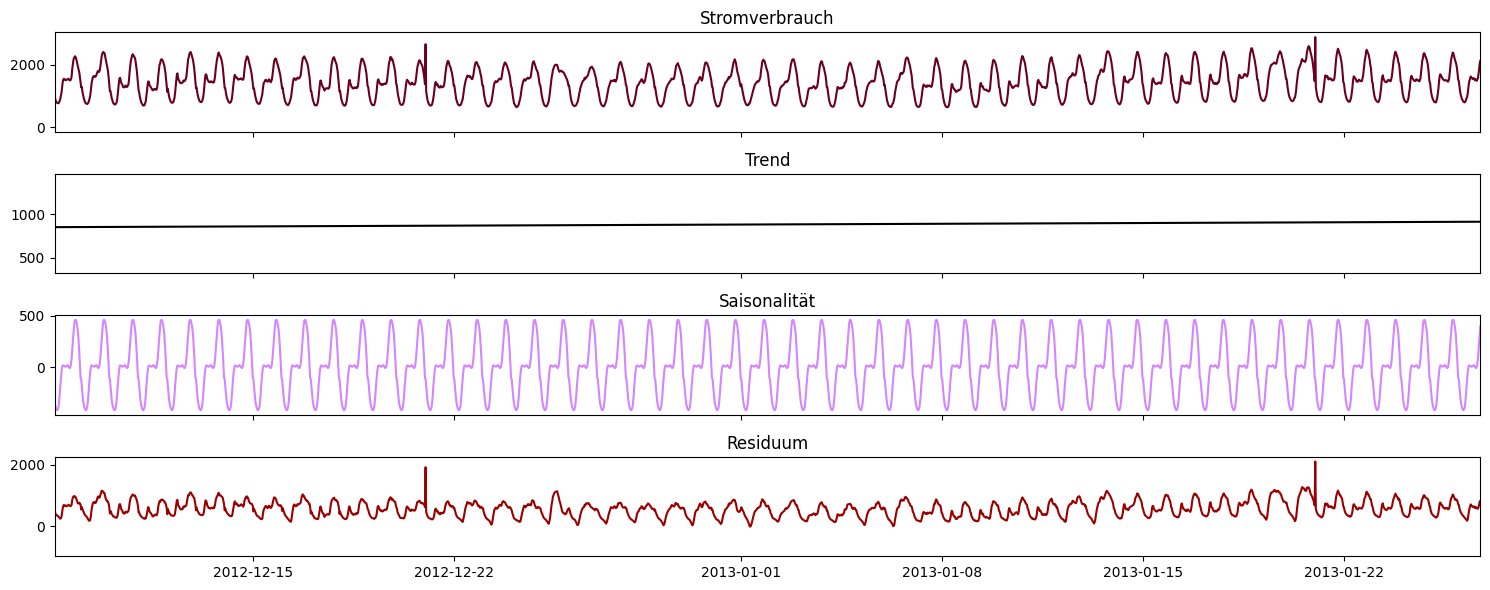

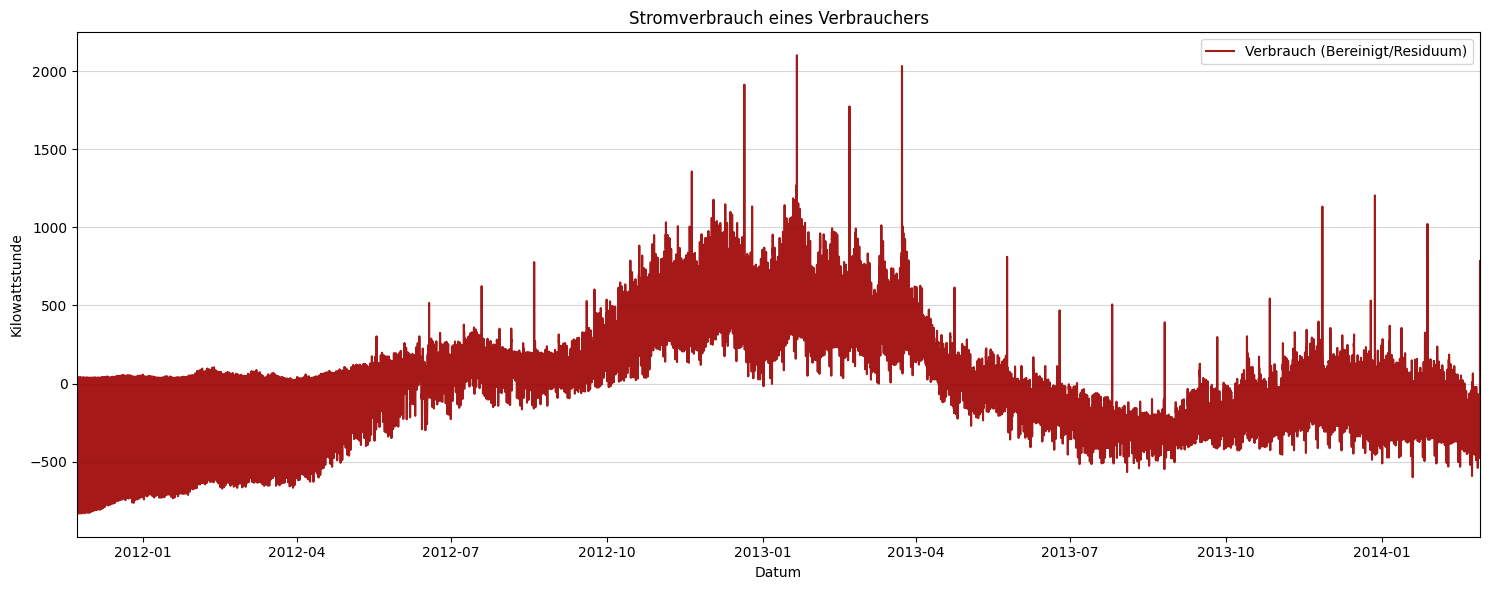

In [8]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    _, ax = plt.subplots(figsize=(15, 6))

    # Berechnung der bereinigte Zeitreihe bzw. dem Residuum/Rest
    df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.5, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
    ax.plot(df.index, df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7, label="Saisonalität")
    ax.set(
        title="Stromverbrauch eines Verbrauchers (Fokus auf Zeitraum)",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    # Begrenzung auf Zeitraum zur besseren Lesbarkeit
    ax.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # Getrennte Plots
    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()
    return df


df = analyse_cleaned(df)

---

## Verwendung von STL

Unsere manuelle Zerlegung basiert auf einem einfachen additiven Modell, welches einige Ungenauigkeiten aufweist: Ein linearer Trend ist unzureichend und eine einmalige Mittelung erfasst keine Schwankungen in der Saisonalität über die Zeit.

STL verwendet einen iterativen Prozess, der Trend und Saisonalität wechselseitig verfeinert. Die Loess-Glättung ist dabei robuster gegenüber Ausreißern, und die Saisonalitätskomponente kann sich über den Beobachtungszeitraum hinweg verändern. 

Das Residuum ist dadurch sauberer isoliert und repräsentiert tatsächlich nur den zufälligen Rest.

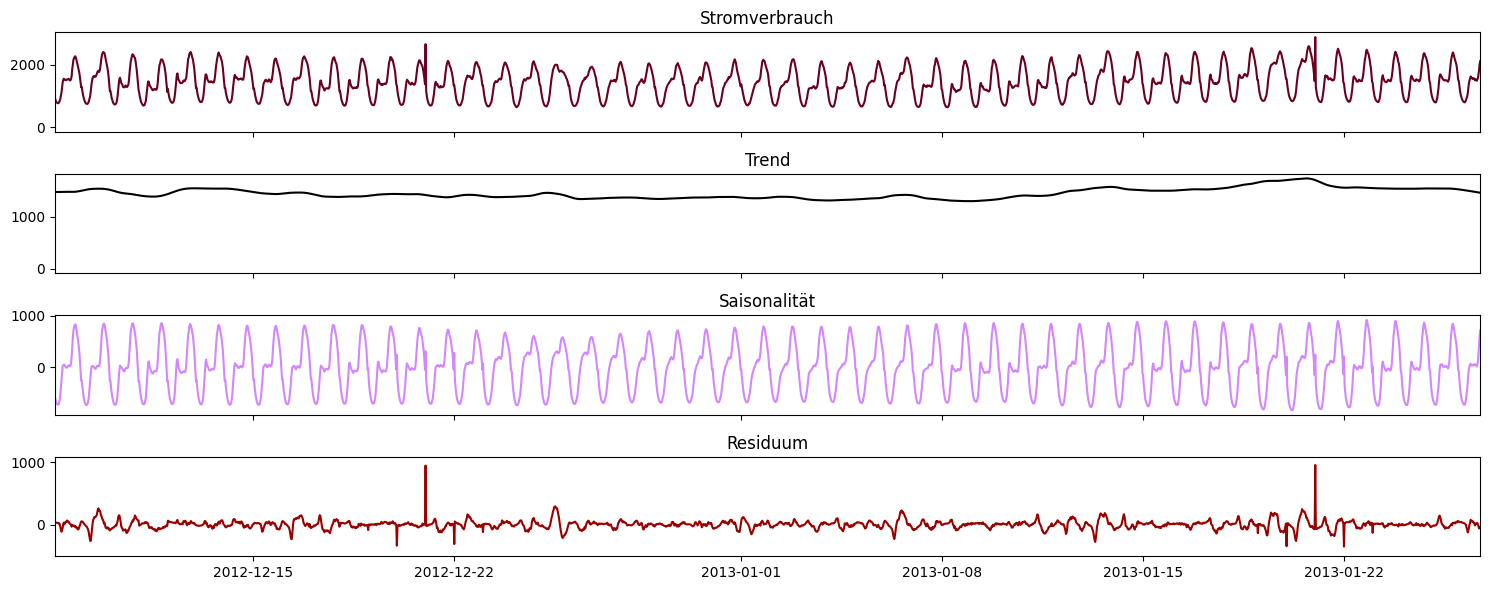

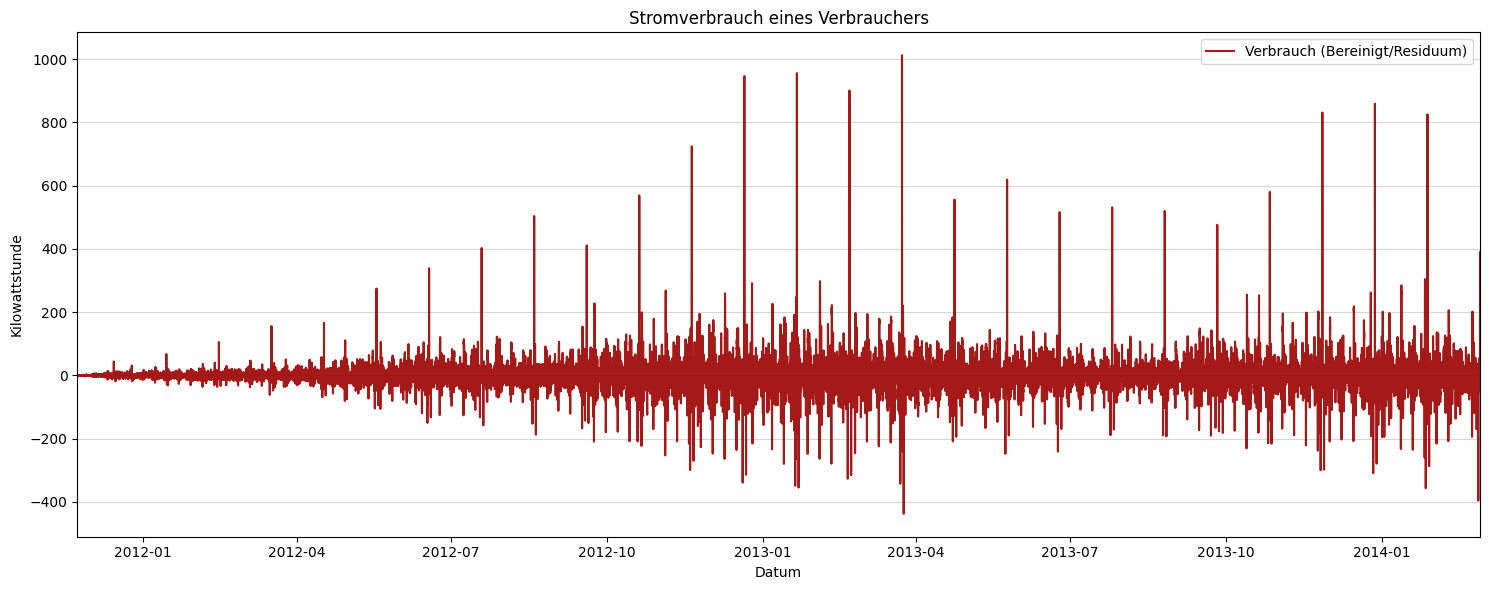

In [9]:
from statsmodels.tsa.seasonal import STL


def plot_STL(df: pd.DataFrame) -> pd.DataFrame:
    decomposition = STL(
        df["kwh"],
        period=48,
    )
    decomposition = decomposition.fit()

    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(decomposition.trend, color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(decomposition.seasonal, color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(decomposition.resid, color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, decomposition.resid, color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return decomposition


decomposition = plot_STL(df)

In [10]:
# Im Folgendem verwenden wir die berechneten Werte der STL-Methode
df["kwh_trend"] = decomposition.trend
df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
df["kwh_trendbereinigt_saison"] = decomposition.seasonal
df["kwh_bereinigt"] = decomposition.resid

---

## Autokorrelation und Partielle Autokorrelation

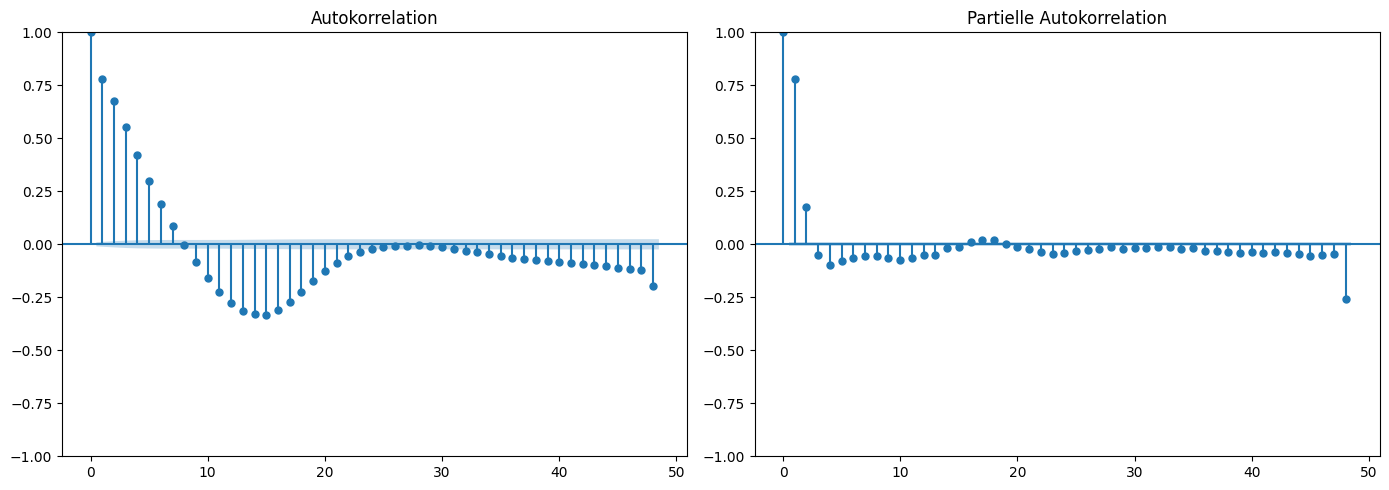

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_, ax = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(df["kwh_bereinigt"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["kwh_bereinigt"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

<font color="orange">
Erkenntnisse: Beim Rest der Reihe (Residuum) lässt sich weiterhin eine leichte Saisonalität (Jahrerythmus) erkennen, was das schwache Ergebnis der Autokorrelation erklären würde. Die Zeitreihe ist also nicht ganz stationär.
</font>

?? Ist das so? Ich hätte gesagt, dass es sich dabei um eine Abhängigkeit jedes Lag auf den vorherigen handelt, wie durch die PACF bestätigt. Laut KI ist das ein AR(1)-Prozess, also die autoregressive Abhängigkeit zum Wert zuvor. 

Außerdem wird der Tagesdurchschnitt betrachtet, der Jahresrythmus sollte hier garnicht erkennbar sein (Dafür müsste der Lag größer sein, oder die Zeiteinteilung angepasst werden).

---

## Vorhersage mit Linearer Regression

Zielvariable hier ist zunächst der tatsächliche Verbrauch 6 Stunden in der Zukunft.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

In [13]:
df_model = df.copy()
# Aufteilung der Trainings- und Testdaten
split = int(len(df_model) * 0.7)
train = df_model.iloc[:split]
test = df_model.iloc[split:]

In [14]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation auf Testdaten

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()  # Nur Train

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)  # Mapping, kein Refit


# Residuum
train["kwh_bereinigt"] = train["kwh_trendbereinigt"] - train["kwh_saison"]
test["kwh_bereinigt"] = test["kwh_trendbereinigt"] - test["kwh_saison"]


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)
    split_df["kwh_bereinigt_t-2"] = split_df["kwh_bereinigt"].shift(2)
    split_df["kwh_bereinigt_t-48"] = split_df["kwh_bereinigt"].shift(48)
    split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
    split_df["kwh_target"] = split_df["kwh"].shift(-12)

train = train.dropna()
test = test.dropna()

In [15]:
# Trainieren des Models
features_a = ["kwh_bereinigt", "kwh_bereinigt_t-1", "kwh_bereinigt_t-2", "kwh_bereinigt_t-48", "kwh_trend", "kwh_saison_t+12", "meters"]

X_train_a = train[features_a]
y_train_a = train["kwh_target"]  # Den um 6 Stunden verschobenen Wert nehmen, nicht den Original Wert
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

# Vorhersage auf Testdaten
X_test_a = test[features_a]
y_pred_a = model_a.predict(X_test_a)

In [16]:
def plot_pred(test: pd.DataFrame, pred: np.ndarray, col: str) -> None:
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(test.index, test[col], color="#6B001E", alpha=0.7, label="Tatsächlicher Verbrauch")
    ax.plot(test.index, pred, color="#0029BC", alpha=1, label="Prognose")

    ax.set(
        title="Prognose 6 Stunden in die Zukunft",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.set_xlim(pd.Series(test.index).quantile(0.0), pd.Series(test.index).quantile(0.1))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


def show_metrics(y_test: np.ndarray, pred: np.ndarray, model: LinearRegression) -> None:
    print(
        f"Regression Intercept: {model.intercept_}\n"
        f"Regression Coefficients: {model.coef_}\n"
        f"R²:\t{r2_score(y_test, pred): .6f}\n"
        f"MSE:\t{mean_squared_error(y_test, pred): .6f}\n"
        f"RMSE:\t{root_mean_squared_error(y_test, pred): .6f}\n"
        f"MAE:\t{mean_absolute_error(y_test, pred): .6f}\n"
    )

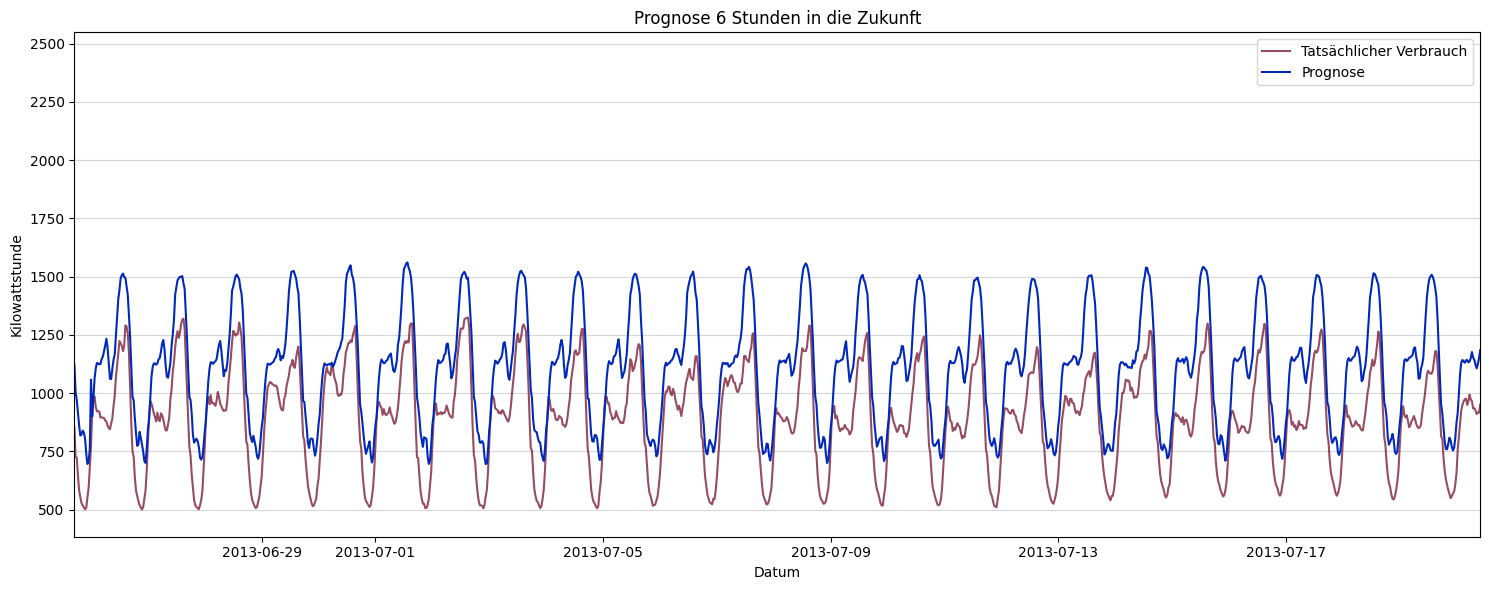

Regression Intercept: -21.819503953981098
Regression Coefficients: [ 0.61727881 -0.30899782 -0.26079006  0.28190981  0.42329991  1.00242168
  0.12987556]
R²:	 0.656249
MSE:	 47420.818708
RMSE:	 217.763217
MAE:	 189.415380



In [17]:
plot_pred(test, y_pred_a, "kwh_target")
show_metrics(test["kwh_target"], y_pred_a, model_a)

<font color="orange">
Erkenntnisse: Das Modell erkennt eine gewisse Saisonalität und Trend, kann diese aber nicht vollständig abbilden.
</font>

In [18]:
df_model = df.copy()
# Aufteilung der Trainings- und Testdaten
split = int(len(df_model) * 0.7)
train = df_model.iloc[:split]
test = df_model.iloc[split:]

<font color="orange">
Erkenntnisse: Schlecht.
</font>

In [19]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)


# Residuum
train["kwh_bereinigt"] = train["kwh_trendbereinigt"] - train["kwh_saison"]
test["kwh_bereinigt"] = test["kwh_trendbereinigt"] - test["kwh_saison"]


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)
    split_df["kwh_bereinigt_t-2"] = split_df["kwh_bereinigt"].shift(2)
    split_df["kwh_bereinigt_t-48"] = split_df["kwh_bereinigt"].shift(48)
    
    # Trend und Saison bei t+12 – nur für Rekomposition, nicht als Features
    split_df["kwh_trend_t12"] = split_df["kwh_trend"].shift(-12)
    split_df["kwh_saison_t12"] = split_df["kwh_saison"].shift(-12)
    # Zielwerte
    split_df["kwh_target"] = split_df["kwh_bereinigt"].shift(-12)
    split_df["kwh_target_final"] = split_df["kwh"].shift(-12)

train = train.dropna()
test = test.dropna()


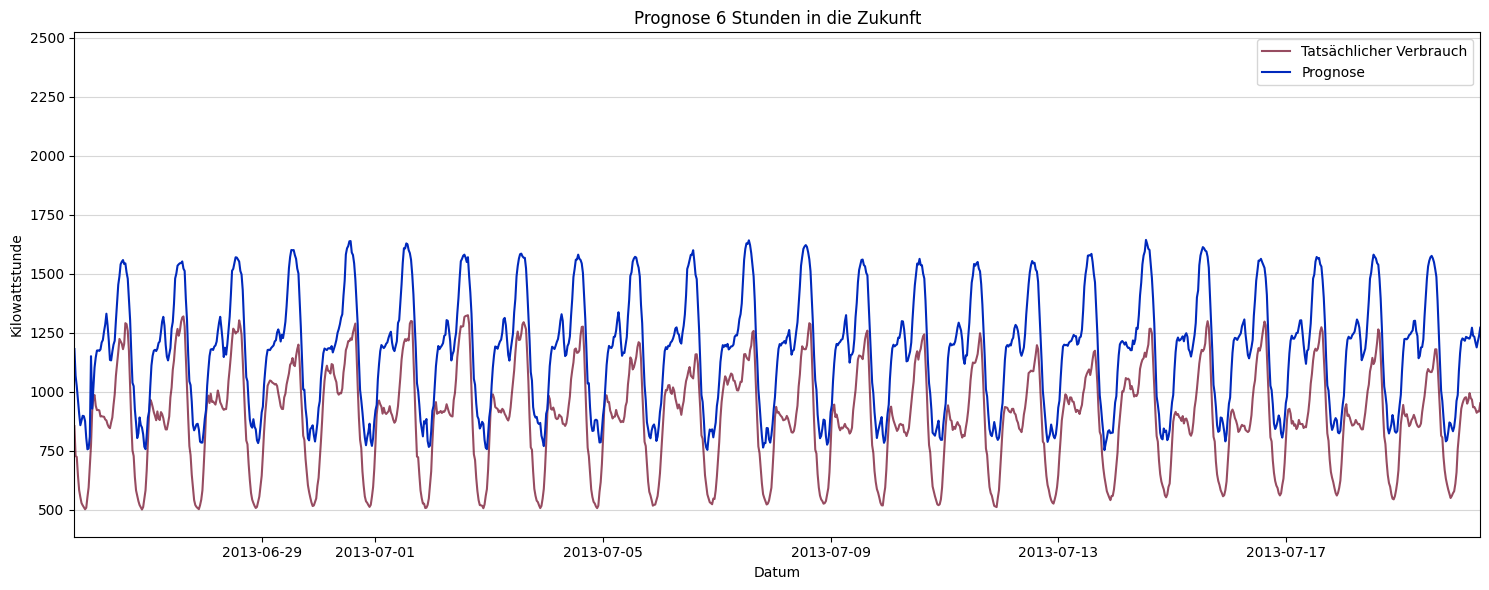

Regression Intercept: -0.22903068277398764
Regression Coefficients: [ 0.84768441 -0.54854587 -0.06541175  0.3412874 ]
R²:	-0.002727
MSE:	 138327.478634
RMSE:	 371.924023
MAE:	 329.756488



In [20]:
features_b = ["kwh_bereinigt", "kwh_bereinigt_t-1", "kwh_bereinigt_t-2", "kwh_bereinigt_t-48"]
# Training (nur Residuum-Lags als Features)
X_train = train[features_b]
y_train = train["kwh_target"]

model_b = LinearRegression()
model_b.fit(X_train, y_train)

# Vorhersage der Testdaten
X_test_b = test[features_b]
y_pred_residuum = model_b.predict(X_test_b)  # Nur das Residuum wird hier vorhergesagt

# Trend und Saisonalität bei t+12 liegen durch .shift(-12) bereits im test-Index vor
y_pred_b = y_pred_residuum + test["kwh_trend_t12"] + test["kwh_saison_t12"]

plot_pred(test, y_pred_b, "kwh_target_final")
show_metrics(test["kwh_target_final"], y_pred_b, model_b)

---

Als Zielvariable wird nun das Residuum 6 Stunden in der Zukunft verwendet.

Für die eigentliche Vorhersage werden der zuvor berechnete Trend und Saisonalität wieder einberechnet. 

<font color="orange">
Erkenntnisse: Besser.
</font>

## Varianzen

In [21]:
# # Berechnung der Varianzen
# def variances(df: pd.DataFrame):
#     df_var = df.copy()

#     df_var["trend"] = df_var["kwh_trend"]
#     df_var["seasonal"] = df_var["kwh_trendbereinigt_saison"]
#     df_var["resid"] = df_var["kwh_bereinigt"]

#     variances = df_var[["kwh", "trend", "seasonal", "resid"]].var()
#     variances["ryth"] = df_var["seasonal"].var()
#     portions = variances / variances["kwh"]

#     print(
#         f"Von der Varianz der Zeitreihe werden:\n\t{(portions['trend'] * 100):2.1f}% durch den Trend erklärt"
#         f"\n\t{(portions['ryth'] * 100):2.1f}% durch die Periodizität erklärt"
#         f"\n\t{(portions['resid'] * 100):2.1f}% haben andere Ursachen (Residuum)"
#     )


# variances(df)

## Vergleich beider Tarife

In [22]:
# df = pd.read_csv("data.csv")


# def prep_data(df: pd.DataFrame, rate: str) -> pd.DataFrame:
#     df["date"] = pd.to_datetime(df["DateTime"])
#     df = df.loc[df["rate"] == rate]
#     df["kwh"] = df["KWH"] / df["meters"]
#     return df[["date", "KWH", "kwh", "meters"]].set_index("date")[["kwh"]].sort_index().asfreq("30min")


# def analyse(df: pd.DataFrame) -> pd.DataFrame:
#     decomposition = plot_STL(analyse_seasonality(analyse_trend(df)))
#     df["kwh_trend"] = decomposition.trend
#     df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
#     df["kwh_trendbereinigt_saison"] = decomposition.seasonal
#     df["kwh_bereinigt"] = decomposition.resid
#     return df


# df_std = prep_data(df, "Std")
# df_tou = prep_data(df, "ToU")

#### Standard Tarif

In [23]:
# variances(analyse(df_std))

#### Variabler Tarif

In [24]:
# variances(analyse(df_tou))

<font color="orange">
Erkenntnisse: TODO!
</font>